# Этап 4b. Проверка H2: время доезда при перегрузке

**Гипотеза H2:** время доезда растёт **нелинейно**: +15–20 % вызовов дают +50–75 % ко времени ожидания, потому что система работает на пределе.

**Идея проверки.** Сравниваем каждый день с «обычным» днём того же района, года, месяца и дня недели:
- **нагрузка** — на сколько % вызовов больше обычного;
- **время доезда** — на сколько % медиана доезда больше обычной.

Если H2 верна, график «нагрузка → время доезда» будет загибаться вверх: при малой перегрузке почти ничего, при большой резкий рост.

*Этот ноутбук написал Claude, чтобы ускорить работу. Твоя задача: прочитать, понять каждую ячейку и задать вопросы.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

df = pd.read_parquet("../data/processed/daily_borough.parquet")
df = df[~df["is_covid"]].copy()          # без COVID, как в этапе 4

## 1. «Обычный день» и отклонения от него

`groupby(...).transform("mean")` считает среднее по группе и **возвращает его в каждую строку** группы (в отличие от `.agg`, который сжимает группу в одну строку). Так у каждого дня появляется «норма» для сравнения.

`resp_median` — медиана времени доезда за день в районе, в секундах.

In [2]:
groups = ["borough", "year", "month", "weekday"]

df["load_pct"] = (df["n_calls"]     / df.groupby(groups)["n_calls"].transform("mean")     - 1) * 100
df["resp_pct"] = (df["resp_median"] / df.groupby(groups)["resp_median"].transform("mean") - 1) * 100

## 2. Главный график: перегрузка → время доезда

In [3]:
bins = [-50, -20, -10, -5, 0, 5, 10, 15, 20, 30, 100]
df["load_bin"] = pd.cut(df["load_pct"], bins=bins)

tab = (df.groupby("load_bin", observed=True)
         .agg(days=("resp_pct", "size"),
              load=("load_pct", "mean"),
              resp=("resp_pct", "mean"))
         .round(1))
tab

,days,load,resp
load_bin,,,
"(-50, -20]",22,-22.6,-14.8
"(-20, -10]",629,-12.8,-7.3
"(-10, -5]",2291,-7.0,-5.0
"(-5, 0]",5257,-2.3,-1.9
"(0, 5]",4877,2.3,1.6
"(5, 10]",2140,7.0,5.3
"(10, 15]",566,12.0,8.3
"(15, 20]",141,17.1,10.8
"(20, 30]",51,22.3,12.7


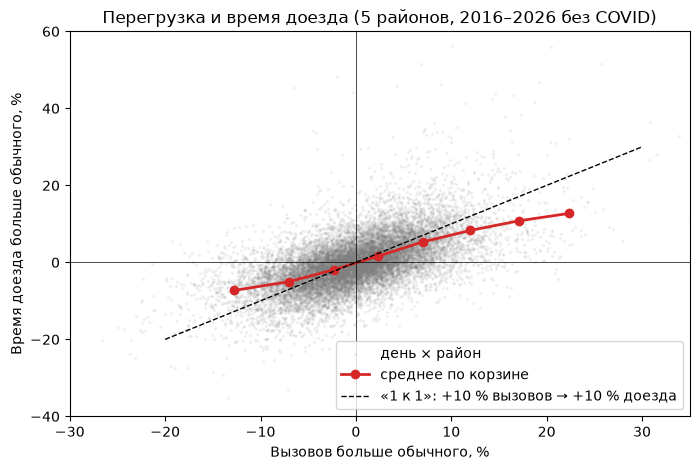

In [4]:
ok = tab[tab["days"] >= 30]          # корзины, где хватает дней для надёжного среднего

plt.figure(figsize=(8, 5))
plt.scatter(df["load_pct"], df["resp_pct"], s=2, alpha=0.08, color="grey", label="день × район")
plt.plot(ok["load"], ok["resp"], "o-", color="tab:red", linewidth=2, label="среднее по корзине")
x = np.linspace(-20, 30, 50)
plt.plot(x, x, "--", color="black", linewidth=1, label="«1 к 1»: +10 % вызовов → +10 % доезда")
plt.xlim(-30, 35); plt.ylim(-40, 60)
plt.axhline(0, color="black", linewidth=0.5); plt.axvline(0, color="black", linewidth=0.5)
plt.xlabel("Вызовов больше обычного, %")
plt.ylabel("Время доезда больше обычного, %")
plt.title("Перегрузка и время доезда (5 районов, 2016–2026 без COVID)")
plt.legend()
plt.show()

**Как читать:** красная линия почти прямая и идёт **ниже** пунктира «1 к 1». При +15–20 % вызовов доезд в среднем растёт примерно на +11 %, а не на +50–75 %. Загиба вверх в диапазоне, где много данных, не видно.

## 3. Проверка моделью: прямая или кривая?

Сравниваем две модели:
- `m_lin`: `resp_pct ~ load_pct` (прямая);
- `m_sq`: добавляем `load_pct²`. Если H2 верна, коэффициент при квадрате будет **положительным и значимым**.

Ошибки считаем с **кластерами по дате**: в один день все 5 районов живут в одной погоде, поэтому их нельзя считать независимыми наблюдениями.

In [5]:
df = df.dropna(subset=["resp_pct"]).reset_index(drop=True)
clusters = {"groups": df["date"].factorize()[0]}

m_lin = smf.ols("resp_pct ~ load_pct", data=df).fit(cov_type="cluster", cov_kwds=clusters)
m_sq  = smf.ols("resp_pct ~ load_pct + I(load_pct**2)", data=df).fit(cov_type="cluster", cov_kwds=clusters)

print(f"Прямая: +1 % вызовов → +{m_lin.params['load_pct']:.2f} % к доезду")
print(f"Квадрат: коэффициент = {m_sq.params['I(load_pct ** 2)']:.4f}, p-value = {m_sq.pvalues['I(load_pct ** 2)']:.2f}")
print(f"AIC: прямая {m_lin.aic:.0f}, с квадратом {m_sq.aic:.0f}")

for load in [10, 15, 20]:
    pred = m_sq.predict(pd.DataFrame({"load_pct": [load]}))[0]
    print(f"  +{load} % вызовов → +{pred:.1f} % к доезду")

Прямая: +1 % вызовов → +0.68 % к доезду
Квадрат: коэффициент = 0.0023, p-value = 0.09
AIC: прямая 100660, с квадратом 100650
  +10 % вызовов → +7.0 % к доезду
  +15 % вызовов → +10.6 % к доезду
  +20 % вызовов → +14.5 % к доезду


## 4. Отдельно: влияет ли жара на доезд **сама по себе**?

Может, в жару доезд хуже не из-за числа вызовов, а из-за пробок, перегрева машин, усталости бригад? Добавим температуру выше порога 10 °C (из этапа 4) при той же нагрузке.

In [6]:
df["heat"] = (df["temperature_2m_max"] - 10).clip(lower=0)
m_heat = smf.ols("resp_pct ~ load_pct + heat", data=df).fit(cov_type="cluster", cov_kwds=clusters)
lo, hi = m_heat.conf_int().loc["heat"]
print(f"+1 °C выше 10 °C при той же нагрузке: {m_heat.params['heat']:+.3f} % к доезду  [95 % ДИ {lo:+.3f} … {hi:+.3f}]")

+1 °C выше 10 °C при той же нагрузке: -0.008 % к доезду  [95 % ДИ -0.027 … +0.011]


## 5. Пример: волна жары 23–25 июня 2025

Сравним с «нормой» — средним за 1–14 июня 2025.

In [7]:
city = (df.groupby("date")
          .agg(n_calls=("n_calls", "sum"),
               resp=("resp_median", "median"),
               tmax=("temperature_2m_max", "mean")))

base = city.loc["2025-06-01":"2025-06-14"].mean()
wave = city.loc["2025-06-16":"2025-06-30"].copy()
wave["calls_%"] = ((wave["n_calls"] / base["n_calls"] - 1) * 100).round(1)
wave["resp_%"]  = ((wave["resp"]    / base["resp"]    - 1) * 100).round(1)
wave.round(1)

,n_calls,resp,tmax,calls_%,resp_%
date,,,,,
2025-06-16,4511,529.0,19.8,-2.1,-7.2
2025-06-17,4240,526.0,20.7,-8.0,-7.7
2025-06-18,4548,570.5,26.9,-1.3,0.1
2025-06-19,4429,487.0,30.1,-3.9,-14.6
2025-06-20,4686,555.0,28.1,1.7,-2.6
2025-06-21,4709,557.0,32.1,2.2,-2.3
2025-06-22,4428,543.0,33.8,-3.9,-4.7
2025-06-23,5275,645.0,37.4,14.5,13.2
2025-06-24,5169,604.0,40.2,12.2,6.0


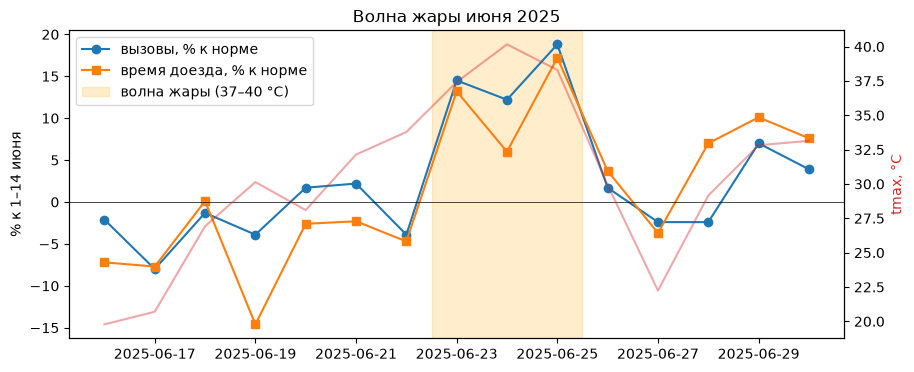

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(wave.index, wave["calls_%"], "o-", label="вызовы, % к норме")
ax.plot(wave.index, wave["resp_%"],  "s-", label="время доезда, % к норме")
ax.axvspan(pd.Timestamp("2025-06-22 12:00"), pd.Timestamp("2025-06-25 12:00"), color="orange", alpha=0.2, label="волна жары (37–40 °C)")
ax.axhline(0, color="black", linewidth=0.5)
ax2 = ax.twinx(); ax2.plot(wave.index, wave["tmax"], color="tab:red", alpha=0.4); ax2.set_ylabel("tmax, °C", color="tab:red")
ax.set_ylabel("% к 1–14 июня"); ax.legend(loc="upper left")
ax.set_title("Волна жары июня 2025")
plt.show()

## 6. Уточнение: «хвост» и срочность вызовов

Медиана показывает **типичный** вызов. Но перегрузка бьёт по тем, кто ждёт дольше всех. Посчитаем по сырым данным для каждого дня и района:
- `p90` — **90-й процентиль** доезда: 10 % вызовов ждали дольше этого времени;
- `med_sev` — медиана доезда для **срочных** вызовов (уровень 1–3, угроза жизни);
- `med_lo` — медиана для **несрочных** (уровень 4 и ниже).

Фильтры те же, что в этапе 3: без `STNDBY`, без `UNKNOWN`, время только валидное (`'Y'`). DuckDB прочитает все ~16 млн строк за секунду.

In [9]:
import duckdb
con = duckdb.connect()
EMS = "../data/raw/ems/*.parquet"

tail = con.sql(f"""
SELECT CAST(incident_datetime AS DATE) AS date,
       borough,
       quantile_cont(incident_response_seconds_qy, 0.9)
           FILTER (WHERE valid_incident_rspns_time_indc = 'Y')                                  AS p90,
       median(incident_response_seconds_qy)
           FILTER (WHERE valid_incident_rspns_time_indc = 'Y' AND initial_severity_level_code <= 3) AS med_sev,
       median(incident_response_seconds_qy)
           FILTER (WHERE valid_incident_rspns_time_indc = 'Y' AND initial_severity_level_code >= 4) AS med_lo
FROM '{EMS}'
WHERE initial_call_type != 'STNDBY' AND borough != 'UNKNOWN'
GROUP BY ALL
""").df()
tail["date"] = pd.to_datetime(tail["date"])

df = df.merge(tail, on=["date", "borough"], how="left")
for col in ["p90", "med_sev", "med_lo"]:
    df[col + "_pct"] = (df[col] / df.groupby(groups)[col].transform("mean") - 1) * 100

(df[["resp_median", "p90", "med_sev", "med_lo"]].median() / 60).round(1).rename("минут (медиана по дням)")

resp_median     7.8
p90            17.0
med_sev         6.6
med_lo          9.0
Name: минут (медиана по дням), dtype: float64

In [10]:
tab2 = (df.groupby("load_bin", observed=True)
          .agg(days=("load_pct", "size"),
               load=("load_pct", "mean"),
               median_all=("resp_pct", "mean"),
               p90=("p90_pct", "mean"),
               severe=("med_sev_pct", "mean"),
               non_severe=("med_lo_pct", "mean"))
          .round(1))
tab2

,days,load,median_all,p90,severe,non_severe
load_bin,,,,,,
"(-50, -20]",22,-22.6,-14.8,-36.1,-7.6,-23.3
"(-20, -10]",629,-12.8,-7.3,-19.5,-3.5,-11.6
"(-10, -5]",2291,-7.0,-5.0,-14.7,-2.4,-8.5
"(-5, 0]",5257,-2.3,-1.9,-6.1,-0.9,-3.4
"(0, 5]",4877,2.3,1.6,4.4,0.7,2.6
"(5, 10]",2140,7.0,5.3,16.3,2.5,9.5
"(10, 15]",566,12.0,8.3,26.1,4.3,14.3
"(15, 20]",141,17.1,10.8,35.2,5.7,19.0
"(20, 30]",51,22.3,12.7,44.7,7.2,21.6


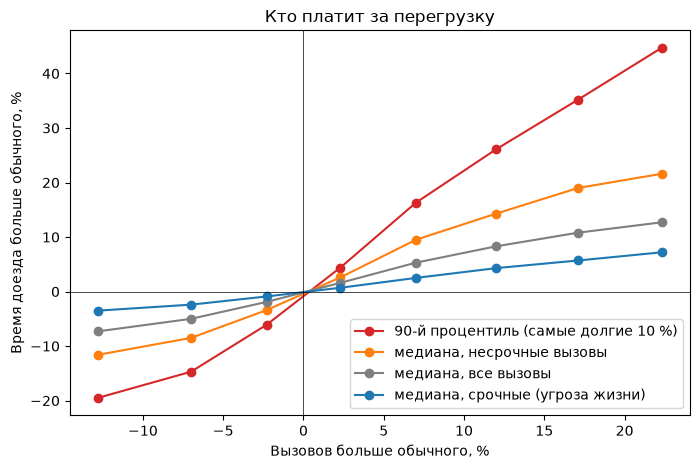

In [11]:
ok2 = tab2[tab2["days"] >= 30]

plt.figure(figsize=(8, 5))
plt.plot(ok2["load"], ok2["p90"],        "o-", color="tab:red",    label="90-й процентиль (самые долгие 10 %)")
plt.plot(ok2["load"], ok2["non_severe"], "o-", color="tab:orange", label="медиана, несрочные вызовы")
plt.plot(ok2["load"], ok2["median_all"], "o-", color="tab:grey",   label="медиана, все вызовы")
plt.plot(ok2["load"], ok2["severe"],     "o-", color="tab:blue",   label="медиана, срочные (угроза жизни)")
plt.axhline(0, color="black", linewidth=0.5); plt.axvline(0, color="black", linewidth=0.5)
plt.xlabel("Вызовов больше обычного, %")
plt.ylabel("Время доезда больше обычного, %")
plt.title("Кто платит за перегрузку")
plt.legend()
plt.show()

In [12]:
print("Прогноз модели с квадратом (+10 / +20 / +30 % вызовов):")
for col, name in [("resp_pct", "медиана, все"), ("p90_pct", "90-й процентиль"),
                  ("med_sev_pct", "срочные"), ("med_lo_pct", "несрочные")]:
    x = df.dropna(subset=[col])
    m = smf.ols(f"{col} ~ load_pct + I(load_pct**2)", data=x).fit(
        cov_type="cluster", cov_kwds={"groups": x["date"].factorize()[0]})
    pred = m.predict(pd.DataFrame({"load_pct": [10, 20, 30]})).round(0).astype(int).tolist()
    print(f"  {name:17s} {pred}   квадрат: p = {m.pvalues['I(load_pct ** 2)']:.3f}")

Прогноз модели с квадратом (+10 / +20 / +30 % вызовов):
  медиана, все      [7, 14, 22]   квадрат: p = 0.092
  90-й процентиль   [22, 50, 84]   квадрат: p = 0.000
  срочные           [3, 7, 12]   квадрат: p = 0.085
  несрочные         [12, 26, 41]   квадрат: p = 0.002


**Как читать:**
- **Срочные вызовы защищены:** даже при +20 % нагрузки их доезд растёт всего на ~+7 %. Диспетчеры отправляют свободную бригаду сначала на угрозу жизни.
- **Расплачиваются несрочные вызовы** (~+26 % при +20 % нагрузки) и особенно **хвост:** 90-й процентиль растёт на **~+50 % при +20 %** нагрузки и на **~+84 % при +30 %**, и кривая загибается вверх (квадрат значим).
- Это ровно та нелинейность, которую обещала H2. Её не было видно в медиане, потому что очередь «копится» в хвосте.

## 7. Пиковые часы

Может, в сутках перегрузка размазана, а в пиковый час всё гораздо хуже? Повторим анализ для **часа × района** (норма — тот же район, год, месяц, день недели **и час**).

In [13]:
hourly = con.sql(f"""
SELECT CAST(incident_datetime AS DATE) AS date, hour(incident_datetime) AS hour, borough,
       count(*) AS n,
       median(incident_response_seconds_qy) FILTER (WHERE valid_incident_rspns_time_indc = 'Y') AS med
FROM '{EMS}'
WHERE initial_call_type != 'STNDBY' AND borough != 'UNKNOWN'
GROUP BY ALL
""").df()
hourly["date"] = pd.to_datetime(hourly["date"])
hourly = hourly.merge(df[["date", "borough"] + groups[1:]].drop_duplicates(), on=["date", "borough"])  # только дни без COVID

hg = groups + ["hour"]
hourly["load_pct"] = (hourly["n"]   / hourly.groupby(hg)["n"].transform("mean")   - 1) * 100
hourly["resp_pct"] = (hourly["med"] / hourly.groupby(hg)["med"].transform("mean") - 1) * 100
hourly["load_bin"] = pd.cut(hourly["load_pct"], [-100, -40, -20, -10, 0, 10, 20, 40, 60, 100, 1000])

hourly.groupby("load_bin", observed=True).agg(hours=("resp_pct", "size"),
                                              load=("load_pct", "mean"),
                                              resp=("resp_pct", "mean")).round(1)

,hours,load,resp
load_bin,,,
"(-100, -40]",11210,-53.0,-5.4
"(-40, -20]",39118,-27.4,-6.8
"(-20, -10]",60173,-14.7,-4.8
"(-10, 0]",89165,-4.7,-2.0
"(0, 10]",78027,5.0,1.5
"(10, 20]",54968,14.5,4.6
"(20, 40]",37848,27.6,7.9
"(40, 60]",8075,47.7,9.4
"(60, 100]",3971,73.5,10.5


**Как читать:** по часам связь даже **слабее**, чем по дням: +15 % вызовов за час дают лишь ~+5 % к медиане доезда этого часа. Один «плохой» час система переживает. Проблема — **устойчивая** перегрузка весь день, как в волну жары: очередь накапливается от часа к часу, и долгие вызовы ждут всё дольше.

## Итоги: подтвердилась ли H2?

**Ответ:**
1. **Для типичного вызова — нет.** Медиана доезда растёт почти пропорционально нагрузке: +1 % вызовов → ~+0,7 % к доезду; при +15–20 % вызовов это +11–15 %, а не +50–75 %.
2. **Для хвоста — да.** 90-й процентиль доезда растёт **нелинейно**: ~+22 % при +10 % нагрузки, **~+50 % при +20 %**, ~+84 % при +30 %. Это и есть «система на пределе» из H2.
3. **Цену платят несрочные вызовы:** их медиана +26 % при +20 % нагрузки, а срочные (угроза жизни) лишь +7 %. Приоритизация диспетчеров работает.
4. Опасна не пиковая минута, а **устойчивая перегрузка на весь день** (волна жары): по часам эффект слабее, чем по суткам.
5. Сама жара при той же нагрузке доезд не ухудшает: всё идёт через число вызовов.

**Сравнение с литературой:** в Лондоне доля вызовов, обслуженных за 8 минут, падает в жару в основном из-за роста числа вызовов (Mahmood et al., 2017). Это согласуется с нашим выводом: жара ухудшает доезд через нагрузку, а не напрямую.

**Ограничения:** дней с перегрузкой выше +20 % мало (~60 день × район), поэтому оценки «при +30 %» неточные. Мы видим связь, а не доказанную причину: в дни перегрузки могут быть и другие проблемы (пробки, сбои связи).

**Что это значит для H4 (расчёт бригад):** целиться надо не в медиану, а в **90-й процентиль** — именно там перегрузка проявляется первой.

**Строка для README:** *Медиана доезда растёт пропорционально нагрузке (+0,7 % на +1 % вызовов), но 90-й процентиль — нелинейно: +20 % вызовов дают ~+50 % к времени ожидания самых долгих 10 % вызовов. Срочные вызовы защищены приоритизацией, расплачиваются несрочные.*